<a href="https://colab.research.google.com/github/Rakshitkumar1/HiddenLayer/blob/main/HiddenLayer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

In [ ]:
dataset=pd.read_csv('/content/50_Startups.csv')
print(dataset.head())
print('')
print(dataset.shape)

   R&D Spend  Administration  Marketing Spend       State     Profit
0  165349.20       136897.80        471784.10    New York  192261.83
1  162597.70       151377.59        443898.53  California  191792.06
2  153441.51       101145.55        407934.54     Florida  191050.39
3  144372.41       118671.85        383199.62    New York  182901.99
4  142107.34        91391.77        366168.42     Florida  166187.94

(50, 5)


In [ ]:
X= np.array(dataset.iloc[:,0:3])
y = np.array(dataset.iloc[:,4])
print(X.shape)
print('input:',X)
print(y.shape)
print('Target:',y)

(50, 3)
input: [[165349.2  136897.8  471784.1 ]
 [162597.7  151377.59 443898.53]
 [153441.51 101145.55 407934.54]
 [144372.41 118671.85 383199.62]
 [142107.34  91391.77 366168.42]
 [131876.9   99814.71 362861.36]
 [134615.46 147198.87 127716.82]
 [130298.13 145530.06 323876.68]
 [120542.52 148718.95 311613.29]
 [123334.88 108679.17 304981.62]
 [101913.08 110594.11 229160.95]
 [100671.96  91790.61 249744.55]
 [ 93863.75 127320.38 249839.44]
 [ 91992.39 135495.07 252664.93]
 [119943.24 156547.42 256512.92]
 [114523.61 122616.84 261776.23]
 [ 78013.11 121597.55 264346.06]
 [ 94657.16 145077.58 282574.31]
 [ 91749.16 114175.79 294919.57]
 [ 86419.7  153514.11      0.  ]
 [ 76253.86 113867.3  298664.47]
 [ 78389.47 153773.43 299737.29]
 [ 73994.56 122782.75 303319.26]
 [ 67532.53 105751.03 304768.73]
 [ 77044.01  99281.34 140574.81]
 [ 64664.71 139553.16 137962.62]
 [ 75328.87 144135.98 134050.07]
 [ 72107.6  127864.55 353183.81]
 [ 66051.52 182645.56 118148.2 ]
 [ 65605.48 153032.06 107138

In [ ]:
print(np.min(X))
print(np.max(X))

0.0
471784.1


In [ ]:
print(np.min(y))
print(np.max(y))

14681.4
192261.83


In [ ]:
X_norm= (X - np.min(X)) /(np.max(X)-np.min(X))
print(X_norm)
y_norm= (y - np.min(y)) /(np.max(y)-np.min(y))
print(y_norm)

[[0.35047641 0.29017044 1.        ]
 [0.3446443  0.320862   0.94089337]
 [0.32523671 0.21438948 0.8646636 ]
 [0.30601373 0.25153847 0.81223513]
 [0.30121265 0.19371524 0.77613557]
 [0.27952807 0.21156862 0.76912588]
 [0.28533276 0.31200473 0.27071031]
 [0.27618169 0.3084675  0.68649342]
 [0.25550357 0.31522671 0.66049977]
 [0.26142229 0.23035785 0.64644319]
 [0.21601635 0.23441678 0.48573267]
 [0.21338566 0.19456063 0.52936195]
 [0.19895488 0.26987001 0.52956308]
 [0.19498832 0.28719719 0.53555202]
 [0.25423332 0.33182004 0.54370828]
 [0.2427458  0.25990032 0.55486446]
 [0.16535765 0.25773982 0.56031151]
 [0.2006366  0.30750841 0.59894835]
 [0.19447277 0.24200856 0.62511553]
 [0.18317637 0.3253906  0.        ]
 [0.16162872 0.24135468 0.63305328]
 [0.16615539 0.32594026 0.63532724]
 [0.15683988 0.26025199 0.64291963]
 [0.14314287 0.22415132 0.64599195]
 [0.16330353 0.21043808 0.29796428]
 [0.1370642  0.29579878 0.29242745]
 [0.1596681  0.30551259 0.28413435]
 [0.15284025 0.27102344 0.74

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(X_norm, y_norm, test_size = 0.2)
print(x_train.shape)
print(x_test.shape)

(40, 3)
(10, 3)


In [ ]:
def initialize_params(x):
 w1 = np.random.randn(5, x.shape[1])
 w2 = np.random.randn(1, 5)
 b1 = np.random.randn(5, 1)
 b2 = np.random.randn(1, 1)
 return w1,w2,b1,b2
def sigmoid_act(x):
 s = 1/(1+np.exp(-x))
 return s
def forward_path(X_train,w1,b1,w2,b2):


 z1 = np.matmul(w1, X_train.T)+b1
 A1 = sigmoid_act(z1)
 z2 = np.matmul(w2, A1)+b2
 A2 = z2
 return A2,A1
def compute_cost(Y_pred, Y_train):
 cost = np.mean((Y_pred - Y_train)**2)
 return cost
def backward_path(A2,A1,w2,Y_train,X_train):

 dA2 = (2*(A2-Y_train))/len(Y_train)
 dz2 = dA2
 dw2 = np.matmul(dz2,A1.T)
 db2 = dz2.sum(axis=1)

 dA1 = np.matmul(w2.T,dz2)
 dz1 = np.multiply(dA1,A1*(1-A1))
 dw1 = np.matmul(dz1,X_train)
 db1 = dz1.sum(axis=1)
 return dw2,dw1,db2,db1
def update_params(w,b,dw,db,learning_rate):
 w = w - learning_rate * dw
 db = np.reshape(db,b.shape)
 b = b - learning_rate * db
 return w,b

In [ ]:
num_iters = 500
learning_rate = 0.001
his1 = []
w1,w2,b1,b2 = initialize_params(x_train)
for i in range(num_iters):
 A2, A1 = forward_path(x_train,w1,b1,w2,b2)
 y_pred = A2
 cost = compute_cost(y_pred, y_train)
 dw2,dw1,db2,db1 = backward_path(A2,A1,w2,y_train,x_train)
 w2,b2 = update_params(w2,b2,dw2,db2,learning_rate)
 w1,b1 = update_params(w1,b1,dw1,db1,learning_rate)

 his1.append(cost)

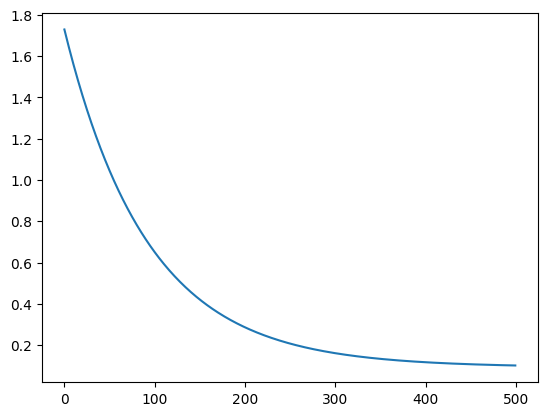

In [ ]:
plt.plot(his1)


In [ ]:
print(w1)
print(b1)

[[ 0.03243191  0.25137879  0.8522079 ]
 [-0.55916613 -1.62440878  1.91671715]
 [ 0.21275413  1.37683196 -0.15998885]
 [-1.70215898 -1.4001653   1.74443446]
 [-1.04868285  0.34776207 -0.72763029]]
[[-1.28592407]
 [ 0.20714532]
 [-0.31654749]
 [-0.00417915]
 [ 0.90020923]]


In [ ]:
print(w2)
print(b2)

[[-0.18529083  0.34065384 -0.70737977 -0.21040746  1.48948367]]
[[0.02899754]]


In [ ]:

def pred(w1,w2,b1,b2,x_test):
 A2, A1 = forward_path(x_test,w1,b1,w2,b2)
 return A2


In [ ]:
y_pred= pred(w1,w2,b1,b2,x_test)
print(y_pred)

[[0.71697788 0.70705969 0.60811402 0.6012241  0.69386563 0.57326757
  0.58086398 0.62647227 0.54022952 0.76661257]]


In [ ]:
print(y_test)
print(y_test.shape)


[0.46596599 0.37348913 0.53874658 0.61710347 0.46627976 0.7606613
 0.66404417 0.79649041 0.80138177 0.        ]
(10,)


In [ ]:

y_pred=np.reshape(y_pred,(len(x_test),1))
print(y_pred)

[[0.71697788]
 [0.70705969]
 [0.60811402]
 [0.6012241 ]
 [0.69386563]
 [0.57326757]
 [0.58086398]
 [0.62647227]
 [0.54022952]
 [0.76661257]]


In [ ]:
y_test_rescalled = (y_test*(y.max()-y.min()))+y.min()
y_pred_rescalled = (y_pred*(y.max()-y.min()))+y.min()
print(y_pred_rescalled)
print(y_test_rescalled)

[[142002.63992442]
 [140241.36298606]
 [122670.54831362]
 [121447.03504015]
 [137898.35613992]
 [116482.50123119]
 [117831.47535529]
 [125930.61553438]
 [110615.58975857]
 [150816.78982355]]
[ 97427.84  81005.76 110352.25 124266.9   97483.56 149759.96 132602.65
 156122.51 156991.12  14681.4 ]


In [ ]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
from math import sqrt
print("MAE :" , mean_absolute_error(y_test,y_pred))
print("RMSE :" , np.sqrt(mean_squared_error(y_test,y_pred)))

MAE : 0.23657720069041224
RMSE : 0.3095113027254734


In [ ]:

calculation = pd.DataFrame(np.c_[y_test_rescalled,y_pred_rescalled], columns = ["Original Profit","Predict Prof"])
calculation

,Original Profit,Predict Prof
0,97427.84,142002.639924
1,81005.76,140241.362986
2,110352.25,122670.548314
3,124266.90,121447.035040
4,97483.56,137898.356140
5,149759.96,116482.501231
6,132602.65,117831.475355
7,156122.51,125930.615534
8,156991.12,110615.589759
9,14681.40,150816.789824


In [ ]:
print(w1)
print(b1)

[[ 0.29801161  0.76986642  0.84915513]
 [ 1.53706349  1.11647203  0.18402724]
 [-0.33865646 -0.3506453  -0.09251999]
 [ 2.82003996 -1.33175128 -0.0317338 ]
 [ 2.66469751  0.52767584 -0.07901642]]
[[ 0.56895038]
 [-0.20646978]
 [-1.21815029]
 [-0.02127699]
 [ 0.70190052]]


In [ ]:
print(w2)
print(b2)

[[ 0.87748937  1.03784428 -0.69917328  1.96075831 -0.06986384]]
[[-1.5526293]]


In [ ]:
def pred2(w1,w2,b1,b2,x_test):
  y_pred=np.zeros(y_test.shape)
  for i in range(len(x_test)):
    A2, A1 = forward_path_sgd(x_test[i],w1,b1,w2,b2)
    y_pred[i]=A2
  return y_pred

In [ ]:
y_pred2= pred2(w1,w2,b1,b2,x_test)
print(y_pred2)
print(y_pred2.shape)

[0.45391842 0.42942223 0.595265   0.66447256 0.45208272 0.78940215
 0.7368416  0.75040412 0.84419787 0.21392228]
(10,)


/tmp/ipykernel_3201/2508102455.py:5: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y_pred[i]=A2


In [ ]:
print(np.min(y_pred2))
print(np.max(y_pred2))

0.21392228176888306
0.8441978668533909


In [ ]:
y_test

array([0.46596599, 0.37348913, 0.53874658, 0.61710347, 0.46627976,
       0.7606613 , 0.66404417, 0.79649041, 0.80138177, 0.        ])

In [ ]:
y_test_rescalled = (y_test*(y.max()-y.min()))+y.min()
y_pred_rescalled = (y_pred2*(y.max()-y.min()))+y.min()
print(y_pred_rescalled)
print(y_test_rescalled)


[ 95288.427357    90938.38374111 120388.81485558 132678.7225092
  94962.44329325 154863.77262189 145530.04896207 147938.48547388
 164594.42020091  52669.8107831 ]
[ 97427.84  81005.76 110352.25 124266.9   97483.56 149759.96 132602.65
 156122.51 156991.12  14681.4 ]


In [ ]:
print(np.min(y_pred_rescalled))
print(np.max(y_pred_rescalled))


52669.81078309941
164594.4202009079


In [ ]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
from math import sqrt
print("MAE :" , mean_absolute_error(y_test,y_pred2))
print("RMSE :" , np.sqrt(mean_squared_error(y_test,y_pred2)))

MAE : 0.05904281657034984
RMSE : 0.08047284188554317
